# SMS Spam Detector
**Mini Project – Text Classification using Python (UCI SMS Spam Collection)**

Submitted by: Jeeva Ragav P | Register No: 71052510009

Department of Computer Science and Engineering (AI & ML), Coimbatore Institute of Engineering and Technology

## Problem Statement
Develop a text-classification system to identify spam SMS messages while **minimizing the incorrect classification of genuine (ham) messages**.

## Objectives
- Load and explore the UCI SMS Spam Collection dataset
- Clean and convert text into TF-IDF numeric features
- Train and compare Naive Bayes, Logistic Regression and Linear SVM
- Tune the decision threshold so genuine messages are rarely marked as spam
- Evaluate with accuracy, precision, recall, F1 and confusion matrix
- Build a prediction function and a simple Streamlit app

## Tools
Python 3, Jupyter Notebook, pandas, numpy, matplotlib, seaborn, scikit-learn, joblib, Streamlit

### Step 1: Import libraries

In [5]:
import os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, precision_recall_curve)

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


### Step 2: Load the UCI SMS Spam Collection dataset
Downloads the dataset from the UCI repository if it is not already in the folder.

In [6]:
URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
FILE = "SMSSpamCollection"

if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, "sms.zip")
    with zipfile.ZipFile("sms.zip") as z:
        z.extractall(".")

df = pd.read_csv(FILE, sep="\t", header=None, names=["label", "message"], encoding="latin-1")
print("Dataset shape:", df.shape)
df.head(10)

Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


**OUTPUT – First 10 rows of the dataset:**

> 📸 *Paste screenshot of the output here*

### Step 3: Explore the data

In [7]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate messages:", df.duplicated().sum())
print("\nClass distribution:\n", df["label"].value_counts())
print("\nSpam percentage: %.2f%%" % (100 * (df["label"] == "spam").mean()))

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None

Missing values:
 label      0
message    0
dtype: int64

Duplicate messages: 403

Class distribution:
 label
ham     4825
spam     747
Name: count, dtype: int64

Spam percentage: 13.41%


**OUTPUT – Dataset information and class distribution:**

> 📸 *Paste screenshot of the output here*

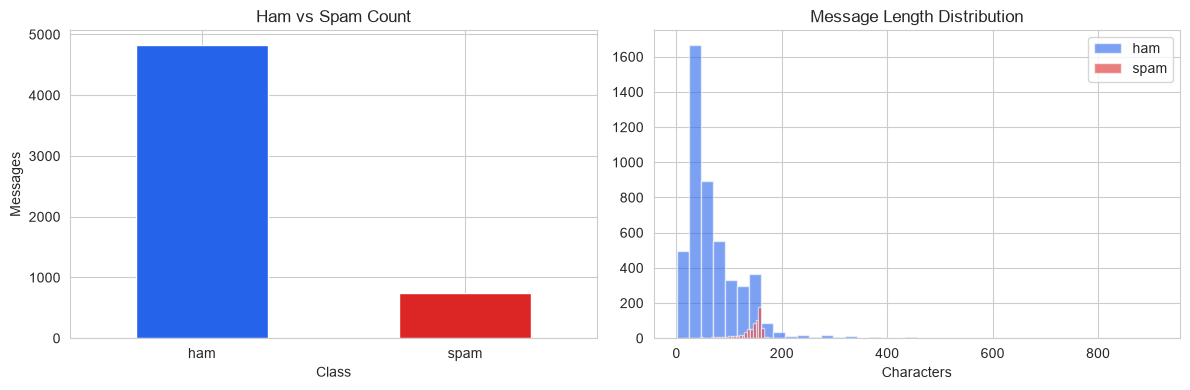

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.558964  58.459702   2.0   33.0   52.0   93.0  910.0
spam    747.0  139.119143  28.998900  13.0  133.0  149.0  158.0  224.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["label"].value_counts().plot(kind="bar", color=["#2563eb", "#dc2626"], ax=ax[0])
ax[0].set_title("Ham vs Spam Count"); ax[0].set_xlabel("Class"); ax[0].set_ylabel("Messages")
ax[0].tick_params(axis="x", rotation=0)

df["length"] = df["message"].str.len()
for lbl, col in [("ham", "#2563eb"), ("spam", "#dc2626")]:
    ax[1].hist(df[df.label == lbl]["length"], bins=40, alpha=0.6, label=lbl, color=col)
ax[1].set_title("Message Length Distribution"); ax[1].set_xlabel("Characters"); ax[1].legend()

plt.tight_layout(); plt.show()
print(df.groupby("label")["length"].describe())

**OUTPUT – Class balance and message length charts:**

> 📸 *Paste screenshot of the output here*

### Step 4: Preprocessing
Labels are converted to numbers (ham = 0, spam = 1). Duplicates are removed so identical messages do not leak between train and test sets. Text cleaning (lowercase, stop-word removal, unigrams + bigrams) is done by the TF-IDF vectorizer inside the pipeline.

In [9]:
df = df.drop_duplicates(subset="message").reset_index(drop=True)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print("Shape after removing duplicates:", df.shape)
print(df["target"].value_counts())

Shape after removing duplicates: (5169, 4)
target
0    4516
1     653
Name: count, dtype: int64


**OUTPUT – Shape after removing duplicates:**

> 📸 *Paste screenshot of the output here*

### Step 5: Train-test split (80% / 20%, stratified)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("Spam in train: %.2f%% | Spam in test: %.2f%%" % (100*y_train.mean(), 100*y_test.mean()))

Training samples: 4135
Testing samples : 1034
Spam in train: 12.62% | Spam in test: 12.67%


**OUTPUT – Train-test split sizes:**

> 📸 *Paste screenshot of the output here*

### Step 6: Build and compare models
Each model is a pipeline of TF-IDF + classifier. They are compared with 5-fold cross-validation on the **training set only**.

In [11]:
def make_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english",
                                  ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", clf),
    ])

models = {
    "Naive Bayes": make_pipeline(MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipeline(LogisticRegression(C=10, max_iter=1000, class_weight="balanced")),
    "Linear SVM": make_pipeline(CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3)),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_probs, rows = {}, []

for name, pipe in models.items():
    p = cross_val_predict(pipe, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
    cv_probs[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, pred),
        "Precision": precision_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred),
        "Ham marked spam (FP)": int(((pred == 1) & (y_train == 0)).sum()),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Accuracy,Precision,Recall,F1,Ham marked spam (FP)
Model,,,,,
Naive Bayes,0.9816,0.9685,0.8831,0.9238,15
Logistic Regression,0.9833,0.9539,0.9119,0.9324,23
Linear SVM,0.9826,0.9536,0.9061,0.9293,23


**OUTPUT – Model comparison table (cross-validation):**

> 📸 *Paste screenshot of the output here*

### Step 7: Tune the threshold to protect genuine messages
The default threshold of 0.5 is not necessarily the best. Here the lowest threshold is chosen where **precision ≥ 98.5%** (very few flagged messages are genuine), which keeps recall as high as possible.

Best model by cross-validated F1: Logistic Regression
Chosen threshold: 0.788


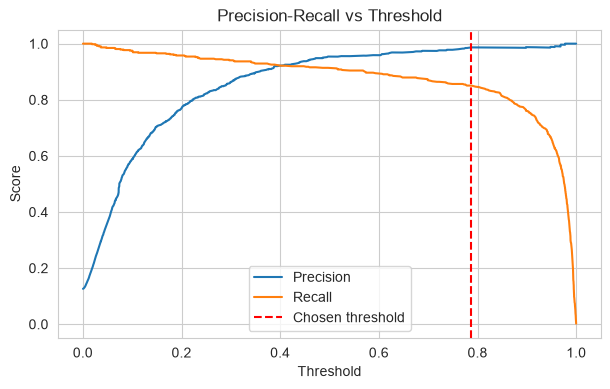

In [12]:
TARGET_PRECISION = 0.985
best_name = comparison["F1"].idxmax()
print("Best model by cross-validated F1:", best_name)

prec, rec, thr = precision_recall_curve(y_train, cv_probs[best_name])
ok = np.where(prec[:-1] >= TARGET_PRECISION)[0]
threshold = float(thr[ok[0]]) if len(ok) else 0.5
print("Chosen threshold: %.3f" % threshold)

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(threshold, color="red", linestyle="--", label="Chosen threshold")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.title("Precision-Recall vs Threshold")
plt.legend(); plt.show()

**OUTPUT – Precision-Recall vs threshold graph:**

> 📸 *Paste screenshot of the output here*

### Step 8: Train the final model and evaluate on the unseen test set

In [13]:
final_model = models[best_name]
final_model.fit(X_train, y_train)

test_probs = final_model.predict_proba(X_test)[:, 1]
y_pred = (test_probs >= threshold).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["ham", "spam"]))

Accuracy : 0.9739
Precision: 0.9727
Recall   : 0.8168
F1-score : 0.888

               precision    recall  f1-score   support

         ham       0.97      1.00      0.99       903
        spam       0.97      0.82      0.89       131

    accuracy                           0.97      1034
   macro avg       0.97      0.91      0.94      1034
weighted avg       0.97      0.97      0.97      1034



**OUTPUT – Test-set metrics and classification report:**

> 📸 *Paste screenshot of the output here*

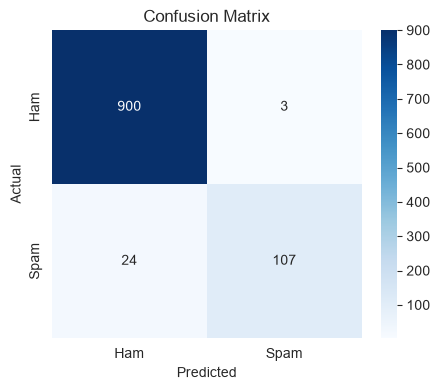

Genuine messages correctly kept : 900
Genuine messages wrongly blocked: 3   <-- the number we want to minimise
Spam correctly caught           : 107
Spam missed                     : 24


In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Genuine messages correctly kept : {tn}")
print(f"Genuine messages wrongly blocked: {fp}   <-- the number we want to minimise")
print(f"Spam correctly caught           : {tp}")
print(f"Spam missed                     : {fn}")

**OUTPUT – Confusion matrix:**

> 📸 *Paste screenshot of the output here*

### Step 9: Inspect the mistakes

In [15]:
errors = pd.DataFrame({"message": X_test.values, "actual": y_test.values,
                       "spam_probability": test_probs.round(3)})
print("Genuine messages wrongly flagged as spam:")
display(errors[(errors.actual == 0) & (test_probs >= threshold)])
print("Spam messages that were missed:")
display(errors[(errors.actual == 1) & (test_probs < threshold)])

Genuine messages wrongly flagged as spam:


,message,actual,spam_probability
327,K k:) sms chat with me.,0,0.984
528,On the road so cant txt,0,0.840
835,I (Career Tel) have added u as a contact on IN...,0,0.823


Spam messages that were missed:


,message,actual,spam_probability
95,Want explicit SEX in 30 secs? Ring 02073162414...,1,0.315
105,You will recieve your tone within the next 24h...,1,0.396
112,Send a logo 2 ur lover - 2 names joined by a h...,1,0.758
168,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1,0.635
174,TheMob>Hit the link to get a premium Pink Pant...,1,0.747
230,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,1,0.126
302,We currently have a message awaiting your coll...,1,0.744
308,Hi its LUCY Hubby at meetins all day Fri & I w...,1,0.122
326,Missed call alert. These numbers called but le...,1,0.228
329,"SMS. ac sun0819 posts HELLO:""You seem cool, wa...",1,0.695


**OUTPUT – Misclassified messages:**

> 📸 *Paste screenshot of the output here*

### Step 10: Top spam-indicating words

In [16]:
tfidf = final_model.named_steps["tfidf"]
words = np.array(tfidf.get_feature_names_out())

# Words most associated with spam, by class-wise average TF-IDF
Xt = tfidf.transform(X_train)
spam_mean = np.asarray(Xt[y_train.values == 1].mean(axis=0)).ravel()
ham_mean  = np.asarray(Xt[y_train.values == 0].mean(axis=0)).ravel()
top = np.argsort(spam_mean - ham_mean)[-15:][::-1]

pd.DataFrame({"word": words[top], "spam_avg_tfidf": spam_mean[top].round(4),
              "ham_avg_tfidf": ham_mean[top].round(4)})

,word,spam_avg_tfidf,ham_avg_tfidf
0,free,0.0369,0.0035
1,txt,0.0263,0.0007
2,mobile,0.0250,0.0007
3,text,0.0263,0.0042
4,reply,0.0238,0.0019
5,claim,0.0219,0.0000
6,stop,0.0238,0.0022
7,www,0.0215,0.0000
8,prize,0.0200,0.0000
9,uk,0.0191,0.0001


**OUTPUT – Top spam words:**

> 📸 *Paste screenshot of the output here*

### Step 11: Predict on new messages

In [17]:
def predict_sms(text):
    prob = final_model.predict_proba([text])[0][1]
    label = "SPAM" if prob >= threshold else "HAM (genuine)"
    return label, round(float(prob), 3)

samples = [
    "Congratulations! You have won a FREE iPhone. Call 09061701461 now to claim your prize!",
    "Hey, are we still meeting for lunch at 1 pm today?",
    "URGENT! Your account is blocked. Click http://bit.ly/xyz to verify and win 5000 cash",
    "Can you send me the lab record before tomorrow's class?",
    "WINNER!! You have been selected for a 1000 pound reward. Text CLAIM to 80086",
    "Mom called, please reach home by 7",
]
for s in samples:
    label, p = predict_sms(s)
    print(f"[{label:13s}] (spam prob {p})  {s}")

[SPAM         ] (spam prob 0.999)  Congratulations! You have won a FREE iPhone. Call 09061701461 now to claim your prize!
[HAM (genuine)] (spam prob 0.007)  Hey, are we still meeting for lunch at 1 pm today?
[SPAM         ] (spam prob 0.981)  URGENT! Your account is blocked. Click http://bit.ly/xyz to verify and win 5000 cash
[HAM (genuine)] (spam prob 0.033)  Can you send me the lab record before tomorrow's class?
[SPAM         ] (spam prob 0.98)  WINNER!! You have been selected for a 1000 pound reward. Text CLAIM to 80086
[HAM (genuine)] (spam prob 0.01)  Mom called, please reach home by 7


**OUTPUT – Predictions on sample messages:**

> 📸 *Paste screenshot of the output here*

### Step 12: Save the model for the app

In [18]:
joblib.dump({"model": final_model, "threshold": threshold}, "spam_model.joblib")
print("Saved spam_model.joblib | threshold =", round(threshold, 3))

Saved spam_model.joblib | threshold = 0.788


**OUTPUT – Model saved message:**

> 📸 *Paste screenshot of the output here*

### Step 13: Streamlit app
The file `app.py` (provided separately) loads `spam_model.joblib`. Run it from a terminal / Anaconda Prompt:

```
pip install streamlit
streamlit run app.py
```

**OUTPUT – App with a spam message:**

> 📸 *Paste screenshot here*

**OUTPUT – App with a genuine message:**

> 📸 *Paste screenshot here*

## Conclusion
The SMS Spam Detector was developed using Python and the UCI SMS Spam Collection dataset. Messages were converted to TF-IDF features and classified with machine-learning models, and the best model was selected using cross-validation. The decision threshold was tuned so that genuine messages are rarely marked as spam, while still catching most spam. The final system is evaluated with accuracy, precision, recall, F1-score and a confusion matrix, and is available as an interactive Streamlit app.